In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers,models
from PIL import Image
import cv2 # for resizing images
import os

In [ ]:
from google.colab import files
uploaded=files.upload()

In [ ]:
#!unzip cats_dogs_light.zip

In [ ]:
test=cv2.imread('cats_dogs_light/train/cat.1.jpg')

In [ ]:
test.shape

(280, 300, 3)

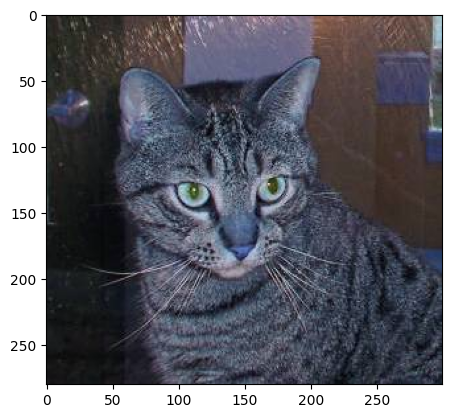

In [ ]:
plt.imshow(test)

In [ ]:
train_dir='cats_dogs_light/train'
test_dir='cats_dogs_light/test'

In [ ]:
train_data=os.listdir(train_dir)
test_data=os.listdir(test_dir)

In [ ]:
train_data

['cat.10085.jpg',
 'dog.10359.jpg',
 'cat.10163.jpg',
 'dog.10406.jpg',
 'dog.10218.jpg',
 'dog.10127.jpg',
 'cat.10301.jpg',
 'dog.101.jpg',
 'dog.10437.jpg',
 'dog.1037.jpg',
 'cat.10132.jpg',
 'dog.10201.jpg',
 'cat.10124.jpg',
 'dog.9960.jpg',
 'cat.10289.jpg',
 'dog.10321.jpg',
 'dog.10342.jpg',
 'dog.10173.jpg',
 'dog.10061.jpg',
 'cat.10018.jpg',
 'cat.10335.jpg',
 'dog.10295.jpg',
 'dog.1044.jpg',
 'cat.10015.jpg',
 'dog.10208.jpg',
 'dog.10312.jpg',
 'dog.10088.jpg',
 'dog.10392.jpg',
 'cat.10395.jpg',
 'dog.10183.jpg',
 'dog.10123.jpg',
 'dog.10333.jpg',
 'dog.10405.jpg',
 'cat.10094.jpg',
 'dog.10073.jpg',
 'dog.10060.jpg',
 'dog.10084.jpg',
 'dog.10104.jpg',
 'cat.10325.jpg',
 'cat.10308.jpg',
 'dog.10258.jpg',
 'cat.10228.jpg',
 'cat.10044.jpg',
 'cat.10150.jpg',
 'cat.10397.jpg',
 'cat.10068.jpg',
 'cat.10199.jpg',
 'dog.10401.jpg',
 'dog.10188.jpg',
 'dog.10137.jpg',
 'dog.10025.jpg',
 'dog.10212.jpg',
 'cat.1031.jpg',
 'cat.10115.jpg',
 'dog.10072.jpg',
 'cat.10280.jpg'

In [ ]:
test_data[1]

'cat.9898.jpg'

In [ ]:
train_images=[]
for image_name in train_data:
  image=cv2.imread(train_dir+'/'+image_name)
  image=cv2.resize(image,(128,128))
  train_images.append(image)

(array([   0.,    0.,    0.,    0.,    0., 1000.,    0.,    0.,    0.,
           0.]),
 array([127.5, 127.6, 127.7, 127.8, 127.9, 128. , 128.1, 128.2, 128.3,
        128.4, 128.5]),
 <BarContainer object of 10 artists>)

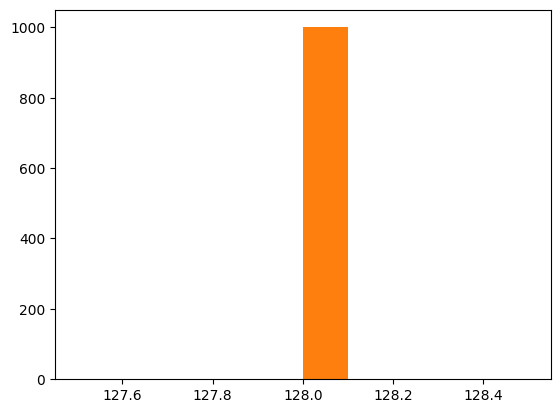

In [ ]:
height=[]
width=[]
for i in train_images:
  height.append(i.shape[0])
  width.append(i.shape[1])
plt.hist(height)
plt.hist(width)

In [ ]:
height=np.array(height)
width=np.array(width)
height.mean(),width.mean()

(np.float64(128.0), np.float64(128.0))

In [ ]:
train_labels = []
for image_name in train_data:
  if 'cat' in image_name:
    train_labels.append(0)
  else:
    train_labels.append(1)
print(train_labels[:10]) # print first 10 labels to verify

[0, 1, 0, 1, 1, 1, 0, 1, 1, 1]


In [ ]:
train_images[0].shape

(128, 128, 3)

In [ ]:
test_images=[]
test_labels=[]
for imge_name in os.listdir(test_dir):
  image=cv2.imread(test_dir+'/'+imge_name)
  image=cv2.resize(image,(128,128))
  test_images.append(image)
  if 'cat' in imge_name:
    test_labels.append(0)
  else:
    test_labels.append(1)

In [ ]:
test_labels[0:10]

[1, 0, 1, 1, 1, 1, 1, 1, 0, 0]

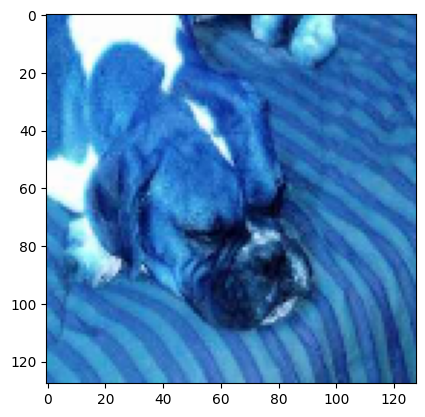

In [ ]:
plt.imshow(test_images[0])

In [ ]:
train_images[0].shape,train_images[1].shape

((128, 128, 3), (128, 128, 3))

In [ ]:
train_labels[0:10]

[0, 1, 0, 1, 1, 1, 0, 1, 1, 1]

In [ ]:
#normalized the pixes range initially -0-255 is 0-1
train_images = np.array(train_images).astype('float32')/255
test_images = np.array(test_images).astype('float32')/255

In [ ]:
train_images.shape

(1000, 128, 128, 3)

In [ ]:
#train_labels = np.array(train_labels)
#test_labels=np.array(test_labels)

In [ ]:
train_labels = tf.keras.utils.to_categorical(train_labels)
test_labels = tf.keras.utils.to_categorical(test_labels)

In [ ]:
train_labels.shape , test_labels.shape

((1000, 2), (399, 2))

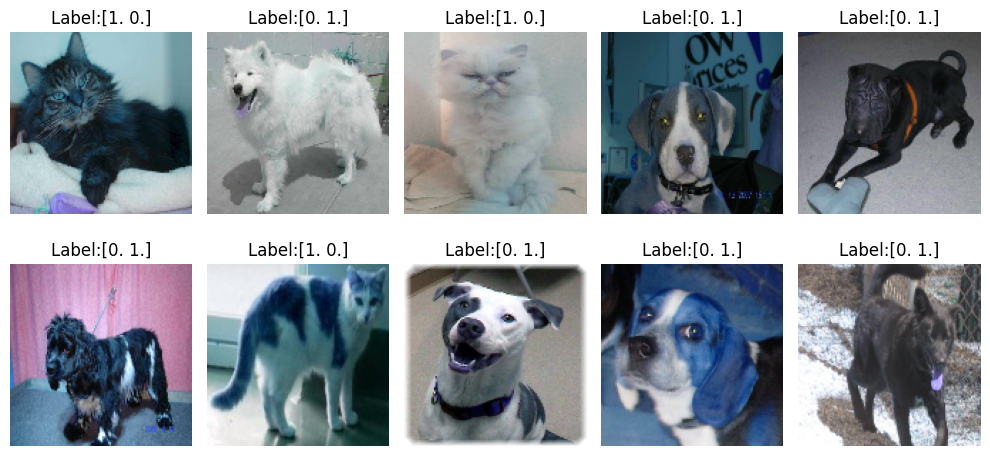

In [ ]:
plt.figure(figsize=(10,5))
for i in range(10):
  plt.subplot(2,5, i+1)
  img = train_images[i]
  plt.imshow(img, cmap='gray')
  plt.title(f"Label:{train_labels[i]}")
  plt.axis('off')
plt.tight_layout()

In [ ]:
data_augmentation=tf.keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.2)
])

In [ ]:
model=models.Sequential([
    data_augmentation,
    layers.Conv2D(32, (3,3),activation='relu',input_shape=(128,128,3)),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2,2),
    layers.Conv2D(64,(3,3),activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2,2),
    layers.Conv2D(128,(3,3),activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2,2),


    layers.Flatten(),
    layers.Dense(128,activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(64,activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(32,activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(2,activation='softmax')
])

In [ ]:
model.summary()

Model: "sequential_36"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_107 (Conv2D)             │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_107         │ (None, 126, 126, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_105               │ (None, 63, 63, 32)     │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_108 (Conv2D)             │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_108         │ (None, 61, 61, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_106               │ (None, 30, 30, 64)     │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_109 (Conv2D)             │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_109         │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_107               │ (None, 14, 14, 128)    │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_35 (Flatten)            │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_144 (Dense)               │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_107 (Dropout)           │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_145 (Dense)               │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_108 (Dropout)           │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_146 (Dense)               │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_109 (Dropout)           │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_147 (Dense)               │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,315,938 (12.65 MB)

 Trainable params: 3,315,490 (12.65 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
model.compile(optimizer='SGD',loss='categorical_crossentropy',metrics=['accuracy'])

In [ ]:
CNN_model=model.fit(train_images, train_labels, epochs=15, batch_size=30, validation_split=0.2)

Epoch 1/15
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.9566 - loss: 0.1051 - val_accuracy: 0.7300 - val_loss: 1.1789
Epoch 2/15
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.9771 - loss: 0.0693 - val_accuracy: 0.7300 - val_loss: 1.1133
Epoch 3/15
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.9623 - loss: 0.0932 - val_accuracy: 0.7450 - val_loss: 1.1866
Epoch 4/15
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.9546 - loss: 0.1102 - val_accuracy: 0.7150 - val_loss: 1.2089
Epoch 5/15
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.9700 - loss: 0.0748 - val_accuracy: 0.7650 - val_loss: 1.3601
Epoch 6/15
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - accuracy: 0.9591 - loss: 0.1115 - val_accuracy: 0.7650 - val_loss: 1.1369
Epoch 7/15
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.9572 - loss: 0.1015 - val_accuracy: 0.7300 - val_loss: 1.0781
Epoch 8/15
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.9611 - loss: 0.1016 - val_accuracy: 0.7150 - v

In [ ]:
model.evaluate(test_images,test_labels)

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.7663 - loss: 1.2069


[1.103377342224121, 0.7493734359741211]

In [ ]:
def predict_image(image_path):
 img = Image.open(image_path)
 plt.imshow(img)
 plt.axis('off')
 plt.show()
 img = img.resize((128,128))
 img_array = np.array(img)
 img_array = img_array.astype('float32')/255
 img_array=img_array.reshape(1,128,128,3)

 result=model.predict(img_array)
 print(result)
 prediction=np.argmax(result)
 print(prediction)
 confidence=np.max(result)
 # Assuming 0 is Cat and 1 is Dog based on your train_labels encoding
 print("Dog" if prediction == 1 else "Cat",confidence)

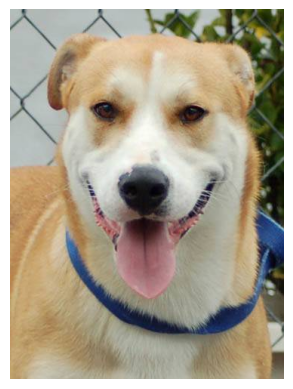

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
[[0.02045121 0.9795488 ]]
1
Dog 0.9795488


In [ ]:
predict_image('/content/dog.1034.jpg')

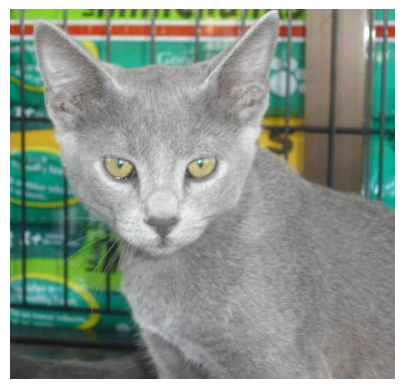

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
[[0.870635   0.12936507]]
0
Cat 0.870635


In [ ]:
predict_image('/content/cat.1013.jpg')